# 01 — Boxes to chase

How many **boxes** (and how much **spend**) for a target chance at an ultra-rare chase card.

Primary example: Yu-Gi-Oh **Grand Master Rare** in Magnificent Monsters / Maestros (Europe pool).

**Key facts**
- These are **3-pack tuckboxes**, not 24-pack boosters.
- Europe pool: **100 serials × 18 cards = 1,800** Grand Master Rares (E suffix).
- Konami published **no per-box rate**. Odds require an assumed print-run size.
- Gemini's "~60 boxes" is not official — it only matches some print-run + target combo (see table below).

Edit `retail_price_sek` in the YAML (or override in the inputs cell).

In [7]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if ROOT.name != "notebooks":
    # allow running from repo root
    if (ROOT / "notebooks").is_dir():
        ROOT = ROOT / "notebooks"
sys.path.insert(0, str(ROOT))

from poke_sim import (
    boxes_for_probability,
    load_product,
    p_from_print_run,
    p_from_rate,
    print_run_sweep,
    prob_at_least_one,
    simulate_boxes_until_hit,
    spend_curve,
)

pd.set_option("display.float_format", lambda x: f"{x:,.4f}" if abs(x) < 10 else f"{x:,.2f}")

## Inputs

Change `PRODUCT`, `MODE`, `TARGET`, and optional retail override.

In [9]:
PRODUCT = "magnificent_monsters"  # or magnificent_maestros
MODE = "any"  # "any" = all 1800 serials; "specific" = 100 for one art
TARGET = 0.50  # e.g. 0.25, 0.50, 0.90
RETAIL_OVERRIDE_SEK = None  # e.g. 420 to override YAML

product = load_product(PRODUCT)
chase = product["chase"]
retail = RETAIL_OVERRIDE_SEK if RETAIL_OVERRIDE_SEK is not None else product["retail_price_sek"]
serials = chase["total_serials_region"] if MODE == "any" else chase["serials_per_card"]
print_runs = chase["print_run_boxes_scenarios"]
label = f"{chase['label']} [{MODE}]"

print(product["name"])
print(f"Retail: {retail} SEK / box | packs_per_box={product['packs_per_box']}")
print(f"Chase: {label} | serials modeled={serials}")
print(product.get("notes", "").strip())

Magnificent Monsters
Retail: 400 SEK / box | packs_per_box=3
Chase: Grand Master Rare (any of 18) [any] | serials modeled=1800
Premium tuckbox (not a 24-pack booster). 3×5 Ultra packs + 3 bonus Secrets. Grand Master Rare: 100 serials × 18 cards = 1800 for Europe/Oceania/Africa/MENA (E suffix). Release ~Sep 2026. No official per-box GMR rate — odds need a print-run assumption.


## Print-run sensitivity

For each assumed Europe-pool print run, boxes and spend to hit each probability target.

In [10]:
sweep = print_run_sweep(
    serials=serials,
    print_runs=print_runs,
    retail=retail,
    targets=(0.10, 0.25, 0.50, 0.75, 0.90),
    label=label,
)
sweep

,print_run_boxes,label,serials,target_prob,target_pct,boxes,spend,p_box
0,50000,Grand Master Rare (any of 18) [any],1800,0.1000,10%,3,1200,0.0360
1,50000,Grand Master Rare (any of 18) [any],1800,0.2500,25%,8,3200,0.0360
2,50000,Grand Master Rare (any of 18) [any],1800,0.5000,50%,19,7600,0.0360
3,50000,Grand Master Rare (any of 18) [any],1800,0.7500,75%,38,15200,0.0360
4,50000,Grand Master Rare (any of 18) [any],1800,0.9000,90%,63,25200,0.0360
5,100000,Grand Master Rare (any of 18) [any],1800,0.1000,10%,6,2400,0.0180
6,100000,Grand Master Rare (any of 18) [any],1800,0.2500,25%,16,6400,0.0180
7,100000,Grand Master Rare (any of 18) [any],1800,0.5000,50%,39,15600,0.0180
8,100000,Grand Master Rare (any of 18) [any],1800,0.7500,75%,77,30800,0.0180
9,100000,Grand Master Rare (any of 18) [any],1800,0.9000,90%,127,50800,0.0180


In [11]:
pivot_boxes = sweep.pivot(index="print_run_boxes", columns="target_pct", values="boxes")
pivot_spend = sweep.pivot(index="print_run_boxes", columns="target_pct", values="spend")
print("Boxes needed")
display(pivot_boxes)
print("Spend (SEK)")
display(pivot_spend)

Boxes needed


target_pct,10%,25%,50%,75%,90%
print_run_boxes,,,,,
50000,3,8,19,38,63
100000,6,16,39,77,127
200000,12,32,77,154,255
500000,30,80,193,385,639


Spend (SEK)


target_pct,10%,25%,50%,75%,90%
print_run_boxes,,,,,
50000,1200,3200,7600,15200,25200
100000,2400,6400,15600,30800,50800
200000,4800,12800,30800,61600,102000
500000,12000,32000,77200,154000,255600


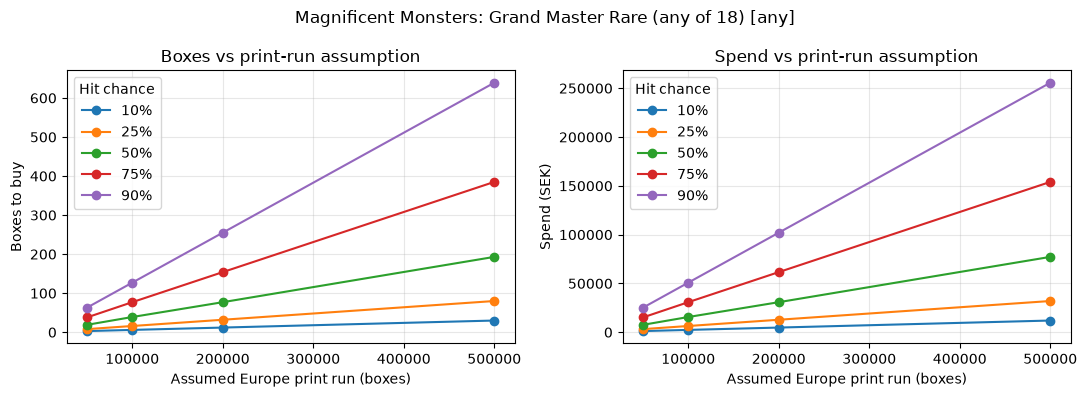

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for target_pct, group in sweep.groupby("target_pct"):
    axes[0].plot(group["print_run_boxes"], group["boxes"], marker="o", label=target_pct)
    axes[1].plot(group["print_run_boxes"], group["spend"], marker="o", label=target_pct)

axes[0].set_xlabel("Assumed Europe print run (boxes)")
axes[0].set_ylabel("Boxes to buy")
axes[0].set_title("Boxes vs print-run assumption")
axes[0].legend(title="Hit chance")
axes[0].grid(True, alpha=0.3)

axes[1].set_xlabel("Assumed Europe print run (boxes)")
axes[1].set_ylabel("Spend (SEK)")
axes[1].set_title("Spend vs print-run assumption")
axes[1].legend(title="Hit chance")
axes[1].grid(True, alpha=0.3)

fig.suptitle(f"{product['name']}: {label}")
fig.tight_layout()
plt.show()

## Takeaway for your chosen target

In [13]:
focus = sweep.loc[sweep["target_prob"] == TARGET].copy()
for _, row in focus.iterrows():
    print(
        f"At print run {int(row['print_run_boxes']):,} boxes: "
        f"buy ~{int(row['boxes'])} boxes (~{row['spend']:,.0f} SEK) "
        f"for {100*TARGET:.0f}% chance of {label}. "
        f"(p_box={row['p_box']:.4f})"
    )

# Where does ~60 boxes land?
print("\n--- Gemini '60 boxes' check ---")
for n in print_runs:
    p = p_from_print_run(serials, n)
    hit = prob_at_least_one(p, 60)
    need_50 = boxes_for_probability(p, 0.5)
    need_90 = boxes_for_probability(p, 0.9)
    print(
        f"print_run={n:,}: 60 boxes => {100*hit:.1f}% hit | "
        f"50% needs {need_50} boxes | 90% needs {need_90} boxes"
    )

At print run 50,000 boxes: buy ~19 boxes (~7,600 SEK) for 50% chance of Grand Master Rare (any of 18) [any]. (p_box=0.0360)
At print run 100,000 boxes: buy ~39 boxes (~15,600 SEK) for 50% chance of Grand Master Rare (any of 18) [any]. (p_box=0.0180)
At print run 200,000 boxes: buy ~77 boxes (~30,800 SEK) for 50% chance of Grand Master Rare (any of 18) [any]. (p_box=0.0090)
At print run 500,000 boxes: buy ~193 boxes (~77,200 SEK) for 50% chance of Grand Master Rare (any of 18) [any]. (p_box=0.0036)

--- Gemini '60 boxes' check ---
print_run=50,000: 60 boxes => 88.9% hit | 50% needs 19 boxes | 90% needs 63 boxes
print_run=100,000: 60 boxes => 66.4% hit | 50% needs 39 boxes | 90% needs 127 boxes
print_run=200,000: 60 boxes => 41.9% hit | 50% needs 77 boxes | 90% needs 255 boxes
print_run=500,000: 60 boxes => 19.5% hit | 50% needs 193 boxes | 90% needs 639 boxes


## Monte Carlo: boxes until first hit

Pick one print-run scenario and see the distribution of "open until first chase".

p_box=0.0180 at print_run=100,000
count   20,000.00
mean        55.32
std         54.74
min        1.0000
50%         38.00
90%        126.00
95%        164.00
max        517.00
Name: boxes_until_hit, dtype: float64


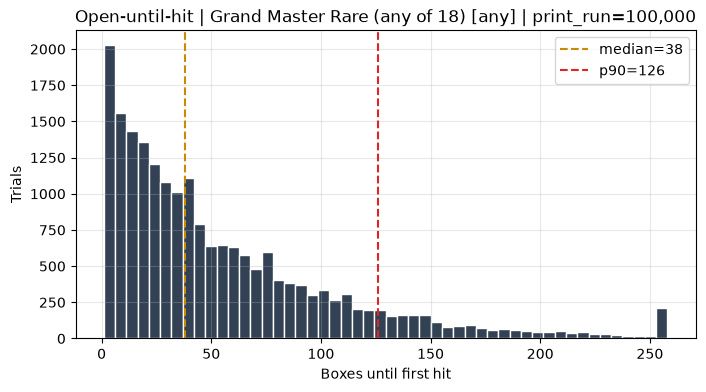

In [15]:
SCENARIO_PRINT_RUN = 100_000
p_box = p_from_print_run(serials, SCENARIO_PRINT_RUN)
until = simulate_boxes_until_hit(p_box, n_trials=20_000)

stats = until["boxes_until_hit"].describe(percentiles=[0.5, 0.9, 0.95])
print(f"p_box={p_box:.4f} at print_run={SCENARIO_PRINT_RUN:,}")
print(stats)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(until["boxes_until_hit"].clip(upper=until["boxes_until_hit"].quantile(0.99)), bins=50, color="#334155", edgecolor="white")
ax.axvline(stats["50%"], color="#ca8a04", linestyle="--", label=f"median={stats['50%']:.0f}")
ax.axvline(stats["90%"], color="#dc2626", linestyle="--", label=f"p90={stats['90%']:.0f}")
ax.set_xlabel("Boxes until first hit")
ax.set_ylabel("Trials")
ax.set_title(f"Open-until-hit | {label} | print_run={SCENARIO_PRINT_RUN:,}")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

## Fixed-rate mode (Starlight / Pokémon-style)

When community data gives hits per box, skip print-run entirely.

In [8]:
fixed = product.get("fixed_rate_chases", [])
if not fixed:
    print("No fixed_rate_chases in this product config.")
else:
    rows = []
    for chase_cfg in fixed:
        p = p_from_rate(chase_cfg["hits_per_box"])
        curve = spend_curve(retail, p)
        curve.insert(0, "chase", chase_cfg["label"])
        curve.insert(1, "hits_per_box", chase_cfg["hits_per_box"])
        rows.append(curve)
    fixed_df = pd.concat(rows, ignore_index=True)
    display(fixed_df)

    # Pokémon sample for comparison
    poke = load_product("sample_pokemon_booster")
    poke_retail = poke["retail_price_sek"]
    poke_p = p_from_rate(poke["chase"]["hits_per_box"])
    print(f"\nPokémon sample ({poke['name']}): retail={poke_retail} SEK, hits/box={poke['chase']['hits_per_box']}")
    display(spend_curve(poke_retail, poke_p))

,chase,hits_per_box,target_prob,target_pct,boxes,spend,p_box
0,Starlight Rare (bonus upgrade — placeholder rate),0.1500,0.1000,10%,1,400,0.1393
1,Starlight Rare (bonus upgrade — placeholder rate),0.1500,0.2500,25%,2,800,0.1393
2,Starlight Rare (bonus upgrade — placeholder rate),0.1500,0.5000,50%,5,2000,0.1393
3,Starlight Rare (bonus upgrade — placeholder rate),0.1500,0.7500,75%,10,4000,0.1393
4,Starlight Rare (bonus upgrade — placeholder rate),0.1500,0.9000,90%,16,6400,0.1393



Pokémon sample (Sample Pokémon Booster Box): retail=1800 SEK, hits/box=0.5


,target_prob,target_pct,boxes,spend,p_box
0,0.1000,10%,1,1800,0.3935
1,0.2500,25%,1,1800,0.3935
2,0.5000,50%,2,3600,0.3935
3,0.7500,75%,3,5400,0.3935
4,0.9000,90%,5,9000,0.3935


### Assumptions reminder

- Independent random boxes; no case mapping.
- `p ≈ serials / print_run` (Bernoulli per box).
- Europe-pool serials only.
- This shows **spend-to-probability**, not a recommendation to rip vs buy singles.